# 01 · EDA Capa Bronze: Auditoría de la Fuente Cruda (SIVIGILA Evento 850)
**Proyecto:** VIGÍA-VIH Medellín (2012–2023)  
**Arquitectura Medallion:** Capa `Bronze` (`data/bronze/sivigila_vih.csv` y `data/bronze/_metadata_bronze.json`)  
**Autora:** Claudia Andrea Cifuentes Hincapié  

---
### Propósito de este Notebook y Reglas Auditadas en la Capa `Bronze`
Este notebook documenta y ejecuta la exploración inicial sobre el archivo crudo oficial del Sistema de Vigilancia en Salud Pública (**SIVIGILA, Evento 850: VIH/SIDA/Mortalidad por SIDA**), sin alterar el archivo fuente original:

1. **Regla 1 (Integridad Criptográfica y Reparación de Mojibake):** Se calcula la huella `SHA-256` del archivo crudo (`15.470 filas × 116 columnas`, separador `;`) y se corrige la codificación *mojibake* (`UTF-8` leído como `cp1252`, ej. `'MedellÃ­n'` $\rightarrow$ `'Medellín'`, `'aÃ±o'` $\rightarrow$ `'año'`).
2. **Regla 2 (Auditoría de Privacidad y Ley 1581 de 2012):** Se identifican los campos nominales y cuasi-identificadores directos que no pueden pasar a las capas analíticas (`ID`, `cer_def_`, `fecha_nto_`, `nreg`, `ocupacion_`, `cod_pre`, `bar_ver_`, `nombre_barrio`, `nom_upgd`, `cod_ase_`).
3. **Regla 3 (Diagnóstico de Fechas Mixtas e Inconsistencias Cronológicas):** Se auditan fechas en formato `dd/mm/aaaa`, seriales numéricos de Excel y vacíos `'-   -'`, cuantificando retrasos negativos (`fec_res > fec_not`), discrepancias entre año epidemiológico y año calendario, y fechas de nacimiento anteriores a 1910.
4. **Regla 4 (Diagnóstico de Unidades de Edad y Rango Biológico):** Se inspecciona `uni_med_` (`1`=Años, `2`=Meses, `3`=Días) y se detectan edades extremas fuera de $[0, 105]$ años.

In [1]:
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = PROJ_ROOT_OVERRIDE if "PROJ_ROOT_OVERRIDE" in globals() else (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import config
from src import etl

raw = etl.leer_crudo(config.RAW_CSV)
meta_bronze = json.loads((config.DIR_BRONZE / "_metadata_bronze.json").read_text(encoding="utf-8"))
print("=== METADATOS DE AUDITORÍA CAPA BRONZE ===")
print(json.dumps(meta_bronze, indent=2, ensure_ascii=False))

=== METADATOS DE AUDITORÍA CAPA BRONZE ===
{
  "archivo": "sivigila_vih.csv",
  "sha256": "ace954c06eeb0a52d1054792a0fb1ff5c74309b747fd06b2062c4dc13df9f00c",
  "n_filas": 15470,
  "n_columnas": 116,
  "fecha_ingesta": "2026-10-29T16:25:58",
  "aviso": "Datos reales de vigilancia (SIVIGILA). Contienen cuasi-identificadores: no publicar."
}


### 1. Perfilado de las Variables Principales en Crudo (`Bronze`)

In [5]:
vars_principales = [
    "ID", "cod_eve", "fec_not", "año", "edad_", "uni_med_", "sexo_",
    "tip_ss_", "mec_pro_t", "area_", "nombre_comuna", "nacionali_",
    "fuente", "est_cli", "pac_hos_", "con_fin_", "fec_con_", "fec_res",
    "fecha_nto_", "nmun_resi", "estrato_",
]

perfil_bronze = pd.DataFrame({
    "Columna_SIVIGILA": vars_principales,
    "No_Nulos": [int(raw[c].notna().sum()) for c in vars_principales],
    "Nulos": [int(raw[c].isna().sum()) for c in vars_principales],
    "Pct_Completitud_Cruda": [round(float(raw[c].notna().mean() * 100), 2) for c in vars_principales],
    "Valores_Unicos": [int(raw[c].nunique(dropna=True)) for c in vars_principales],
    "Ejemplo_Valores": [", ".join(map(str, raw[c].dropna().unique()[:4])) for c in vars_principales]
})
display(perfil_bronze)

,Columna_SIVIGILA,No_Nulos,Nulos,Pct_Completitud_Cruda,Valores_Unicos,Ejemplo_Valores
0,ID,15470,0,100.00,14881,0xAF726EDB4B21FF3D2FACB4E62EB6C302DAF4A56E8685...
1,cod_eve,15470,0,100.00,1,850
2,fec_not,15470,0,100.00,3466,"29/01/2022, 25/02/2021, 11/02/2023, 9/07/2020"
3,año,15470,0,100.00,12,"2022, 2021, 2023, 2020"
4,edad_,15470,0,100.00,85,"27, 26, 33, 59"
5,uni_med_,15470,0,100.00,2,"1, 2"
6,sexo_,15470,0,100.00,2,"M, F"
7,tip_ss_,15470,0,100.00,6,"C, S, E, N"
8,mec_pro_t,15465,5,99.97,12,"1, 3, 2, 6"
9,area_,15470,0,100.00,3,"1, 2, 3"


### 2. Detección Exacta de Anomalías de Calidad en `Bronze` (Reglas 3 y 4)

In [3]:
# 2.1 Evaluación de Edad y Unidad de Medida (uni_med_)
edad_num = pd.to_numeric(raw["edad_"], errors="coerce")
um = raw["uni_med_"]
edad_anios_calc = np.select([um == "1", um == "2", um == "3"], [edad_num, edad_num / 12, edad_num / 365], np.nan)

print("Distribución de uni_med_ (1=Años, 2=Meses, 3=Días):")
display(raw["uni_med_"].value_counts(dropna=False).rename_axis("uni_med_").reset_index(name="frecuencia"))

print("\nRegistros con edad fuera del rango biológico [0, 105] años (se convierten a NaN en Silver):")
fuera_rango = raw.loc[edad_num.notna() & ~((edad_anios_calc >= 0) & (edad_anios_calc <= 105)), ["fec_not", "fecha_nto_", "edad_", "uni_med_", "est_cli"]].copy()
fuera_rango.insert(0, "fila_cruda", fuera_rango.index)
display(fuera_rango)

# 2.2 Fechas de nacimiento inválidas (< 1910)
fnac = etl.parse_fecha(raw["fecha_nto_"])
print("\nFechas de nacimiento anteriores a 1910-01-01:")
fnac_inv = raw.loc[fnac < "1910-01-01", ["fec_not", "fecha_nto_", "edad_", "uni_med_"]].copy()
fnac_inv.insert(0, "fila_cruda", fnac_inv.index)
display(fnac_inv)

# 2.3 Consistencia cronológica
f_not = etl.parse_fecha(raw["fec_not"])
f_res = etl.parse_fecha(raw["fec_res"])
f_con = etl.parse_fecha(raw["fec_con_"])
anio_epi = pd.to_numeric(raw["año"], errors="coerce")

resumen_anomalias = pd.DataFrame([
    {"Regla_Calidad": "Edades fuera de rango biológico [0, 105] años", "Registros_Afectados": int(len(fuera_rango)), "Accion_en_Silver": "Asignar NaN en edad_anios"},
    {"Regla_Calidad": "Fecha de nacimiento anterior a 1910", "Registros_Afectados": int((fnac < "1910-01-01").sum()), "Accion_en_Silver": "Eliminar columna fecha_nto_ (Ley 1581) y anular edad >105"},
    {"Regla_Calidad": "Fecha de resultado laboratorio posterior a notificación (días < 0)", "Registros_Afectados": int(((f_not - f_res).dt.days < 0).sum()), "Accion_en_Silver": "Acotar dias_resultado_notif a [0, 3650]"},
    {"Regla_Calidad": "Año epidemiológico distinto al año calendario de fec_not", "Registros_Afectados": int((f_not.dt.year != anio_epi).sum()), "Accion_en_Silver": "Conservar año epidemiológico oficial y documentar en sensibilidad"}
])
display(resumen_anomalias)

Distribución de uni_med_ (1=Años, 2=Meses, 3=Días):


,uni_med_,frecuencia
0,1,15455
1,2,15



Registros con edad fuera del rango biológico [0, 105] años (se convierten a NaN en Silver):


,fila_cruda,fec_not,fecha_nto_,edad_,uni_med_,est_cli
4656,4656,10/03/2015,6/10/1900,114,1,1
11625,11625,27/01/2023,31/01/1913,109,1,2
12646,12646,15/05/2015,- -,117,1,2



Fechas de nacimiento anteriores a 1910-01-01:


,fila_cruda,fec_not,fecha_nto_,edad_,uni_med_
4656,4656,10/03/2015,6/10/1900,114,1


,Regla_Calidad,Registros_Afectados,Accion_en_Silver
0,"Edades fuera de rango biológico [0, 105] años",3,Asignar NaN en edad_anios
1,Fecha de nacimiento anterior a 1910,1,Eliminar columna fecha_nto_ (Ley 1581) y anula...
2,Fecha de resultado laboratorio posterior a not...,475,"Acotar dias_resultado_notif a [0, 3650]"
3,Año epidemiológico distinto al año calendario ...,269,Conservar año epidemiológico oficial y documen...


### 3. Exploración de las 26 Enfermedades Oportunistas en la Ficha SIVIGILA

,Enfermedad_Oportunista_Columna,Casos_Positivos_Crudos,Pct_Total_Notificaciones
0,tub_pul,433,2.80
1,can_eso,406,2.62
2,otras_micr,227,1.47
3,sin_ema,206,1.33
4,can_va,142,0.92
5,tub_exp,134,0.87
6,neu_pne,130,0.84
7,tox_cer,103,0.67
8,encefalopa,92,0.59
9,sar_kap,75,0.48


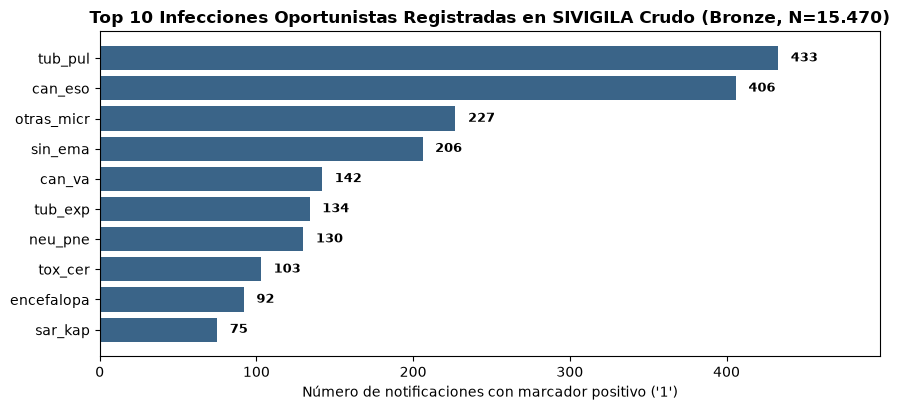

In [4]:
conteo_oport = (raw[etl.OPORTUNISTAS] == "1").sum().sort_values(ascending=False).reset_index()
conteo_oport.columns = ["Enfermedad_Oportunista_Columna", "Casos_Positivos_Crudos"]
conteo_oport["Pct_Total_Notificaciones"] = (conteo_oport["Casos_Positivos_Crudos"] / len(raw) * 100).round(2)
display(conteo_oport.head(12))

fig, ax = plt.subplots(figsize=(9, 4.2))
top10 = conteo_oport.head(10).iloc[::-1]
ax.barh(top10["Enfermedad_Oportunista_Columna"], top10["Casos_Positivos_Crudos"], color="#1F4E78", alpha=0.88)
ax.set_title("Top 10 Infecciones Oportunistas Registradas en SIVIGILA Crudo (Bronze, N=15.470)", fontweight="bold")
ax.set_xlabel("Número de notificaciones con marcador positivo ('1')")
for i, v in enumerate(top10["Casos_Positivos_Crudos"]):
    ax.text(v + 8, i, str(v), va="center", fontsize=9, fontweight="bold")
ax.set_xlim(0, top10["Casos_Positivos_Crudos"].max() * 1.15)
plt.tight_layout()
plt.show()